In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d/dataset_info.json
/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d/skippd-train-00002-of-00005.arrow
/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d/skippd-test.arrow
/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d/skippd-train-00004-of-00005.arrow
/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d/skippd-train-00003-of-00005.arrow
/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d/skippd-train-00001-of-00005.arrow
/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d/skippd-train-00000-of-00005.arrow


In [3]:
import os
import gc
import h5py
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path

print("[STEP 0] Setup")

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

DATASET_ROOT = Path("/kaggle/input/skippd")
HDF5_FILE = DATASET_ROOT / "pv_2019.hdf5"

OUTPUT_ROOT = Path("/kaggle/working/skippd_prepared")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

IMG_H, IMG_W, IMG_C = 64, 64, 3
SEQ_LEN = 8
BATCH_SIZE = 16
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TARGET_YEAR = 2019
AUTOTUNE = tf.data.AUTOTUNE 

2026-04-11 15:07:04.362735: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1775920024.780390      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1775920024.903542      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1775920025.953736      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775920025.953779      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1775920025.953781      55 computation_placer.cc:177] computation placer alr

[STEP 0] Setup


In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("📂", root)
    for f in files:
        print("   └──", f) 

📂 /kaggle/input
📂 /kaggle/input/datasets
📂 /kaggle/input/datasets/eswarvardhankottana
📂 /kaggle/input/datasets/eswarvardhankottana/skippd-dataset
📂 /kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d
   └── dataset_info.json
   └── skippd-train-00002-of-00005.arrow
   └── skippd-test.arrow
   └── skippd-train-00004-of-00005.arrow
   └── skippd-train-00003-of-00005.arrow
   └── skippd-train-00001-of-00005.arrow
   └── skippd-train-00000-of-00005.arrow


In [5]:
print("[STEP 1] Loading Arrow dataset")

from datasets import load_dataset

DATA_PATH = "/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d"

dataset = load_dataset(DATA_PATH)

print(dataset) 

[STEP 1] Loading Arrow dataset


Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'time', 'pv'],
        num_rows: 349372
    })
    test: Dataset({
        features: ['image', 'time', 'pv'],
        num_rows: 14003
    })
})


In [6]:
print(dataset)
print(dataset["train"][0]) 

DatasetDict({
    train: Dataset({
        features: ['image', 'time', 'pv'],
        num_rows: 349372
    })
    test: Dataset({
        features: ['image', 'time', 'pv'],
        num_rows: 14003
    })
})
{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=64x64 at 0x7BCEC5DE43B0>, 'time': datetime.datetime(2017, 3, 9, 6, 47, tzinfo=<DstTzInfo 'US/Pacific' PST-1 day, 16:00:00 STD>), 'pv': 0.05569100379943848}


In [7]:
print("\n[STEP 1] Load + Filter 2019")

from datasets import load_dataset
import numpy as np
import pandas as pd
from pathlib import Path

DATA_PATH = "/kaggle/input/datasets/eswarvardhankottana/skippd-dataset/f51690de73d34cc409670ef6119fd69cc3aade8d"
dataset = load_dataset(DATA_PATH)

train_data = dataset["train"]

images = []
labels = []
timestamps = []

for sample in train_data:
    images.append(np.array(sample["image"]))
    labels.append(sample["pv"])
    timestamps.append(sample["time"])

images = np.array(images)
labels = np.array(labels)
timestamps = pd.DatetimeIndex(timestamps)  # ← make DatetimeIndex

# ✅ FILTER 2019
mask = timestamps.year == 2019  # ← correct for DatetimeIndex

images = images[mask]
labels = labels[mask]
timestamps = timestamps[mask]

print("2019 samples:", len(images))
print("Image shape:", images.shape) 


[STEP 1] Load + Filter 2019
2019 samples: 119941
Image shape: (119941, 64, 64, 3)


In [9]:
import numpy as np
import os

# Create a dedicated folder for your clean data
output_dir = '/kaggle/working/processed_data'
os.makedirs(output_dir, exist_ok=True)

print("[STEP 3] Saving split datasets to disk...")

# Save Features (Images)
np.save(os.path.join(output_dir, 'X_train.npy'), X_train)
np.save(os.path.join(output_dir, 'X_val.npy'), X_val)
np.save(os.path.join(output_dir, 'X_test.npy'), X_test)

# Save Labels (Solar PV Output)
np.save(os.path.join(output_dir, 'y_train.npy'), y_train)
np.save(os.path.join(output_dir, 'y_val.npy'), y_val)
np.save(os.path.join(output_dir, 'y_test.npy'), y_test)

print(f"✅ All datasets successfully saved to {output_dir}")                                       

[STEP 3] Saving split datasets to disk...
✅ All datasets successfully saved to /kaggle/working/processed_data


In [8]:
print("\n[STEP 2] Sorting by time and splitting")

# 1️⃣ Sort by time
idx = np.argsort(timestamps)
images = images[idx]
labels = labels[idx]
timestamps = timestamps[idx]

print("Sorted by time. First timestamp:", timestamps[0])
print("Last timestamp:", timestamps[-1])

# 2️⃣ Split ratios
TRAIN_RATIO = 0.7
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

N = len(images)
n_train = int(N * TRAIN_RATIO)
n_val   = int(N * VAL_RATIO)
n_test  = N - n_train - n_val  # remainder

# 3️⃣ Split into train / val / test
X_train = images[:n_train]
y_train = labels[:n_train]

X_val = images[n_train:n_train+n_val]
y_val = labels[n_train:n_train+n_val]

X_test = images[n_train+n_val:]
y_test = labels[n_train+n_val:]

print(f"Train samples: {X_train.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")
print(f"Test samples: {X_test.shape[0]}") 


[STEP 2] Sorting by time and splitting
Sorted by time. First timestamp: 2019-01-24 07:32:30-08:00
Last timestamp: 2019-10-26 18:59:20-07:00
Train samples: 83958
Validation samples: 17991
Test samples: 17992


Compute dtype  : float16
Variable dtype : float32

[STEP 1] Loading datasets...
  X_train : (83958, 64, 64, 3)  dtype=uint8
  X_val   : (17991, 64, 64, 3)    dtype=uint8
  X_test  : (17992, 64, 64, 3)   dtype=uint8
  y range : [0.0001, 29.5854]  (already 0-1, no scaling needed)

[STEP 2] Building tf.data pipelines...
  Train batch  X:(32, 64, 64, 3) <dtype: 'float32'>   y:(32,) <dtype: 'float32'>

[STEP 3] Building SunNET...


Model: "SunNET_2DCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape      ┃     Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ image_input           │ (None, 64, 64, 3) │           0 │ -                  │
│ (InputLayer)          │                   │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_a_conv (Conv2D)    │ (None, 64, 64,    │         864 │ image_input[0][0]  │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_a_bn               │ (None, 64, 64,    │         128 │ b1_a_conv[0][0]    │
│ (BatchNormalization)  │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_a_relu             │ (None, 64, 64,    │           0 │ b1_a_bn[0][0]      │
│ (Activation)          │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_b_conv (Conv2D)    │ (None, 64, 64,    │       9,216 │ b1_a_relu[0][0]    │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_proj (Conv2D)      │ (None, 64, 64,    │          96 │ image_input[0][0]  │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_b_bn               │ (None, 64, 64,    │         128 │ b1_b_conv[0][0]    │
│ (BatchNormalization)  │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_proj_bn            │ (None, 64, 64,    │         128 │ b1_proj[0][0]      │
│ (BatchNormalization)  │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_add (Add)          │ (None, 64, 64,    │           0 │ b1_b_bn[0][0],     │
│                       │ 32)               │             │ b1_proj_bn[0][0]   │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b1_out (Activation)   │ (None, 64, 64,    │           0 │ b1_add[0][0]       │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ pool1 (MaxPooling2D)  │ (None, 32, 32,    │           0 │ b1_out[0][0]       │
│                       │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ sdrop1                │ (None, 32, 32,    │           0 │ pool1[0][0]        │
│ (SpatialDropout2D)    │ 32)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b2_a_conv (Conv2D)    │ (None, 32, 32,    │      18,432 │ sdrop1[0][0]       │
│                       │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b2_a_bn               │ (None, 32, 32,    │         256 │ b2_a_conv[0][0]    │
│ (BatchNormalization)  │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b2_a_relu             │ (None, 32, 32,    │           0 │ b2_a_bn[0][0]      │
│ (Activation)          │ 64)               │             │                    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ b2_b_conv (Conv2D)    │ (None, 32, 32,    │      36,864 │ b2_a_relu[0][0]    │
│                       │ 64)  

 Total params: 1,427,683 (5.45 MB)

 Trainable params: 1,424,035 (5.43 MB)

 Non-trainable params: 3,648 (14.25 KB)


  Total parameters : 1,427,683

[STEP 4] Training...
Epoch 1/100


I0000 00:00:1775920548.156780     151 service.cc:152] XLA service 0x7bcd0c034b80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1775920548.156827     151 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1775920551.172370     151 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1775920589.287508     151 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2621/2623 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2.9708 - mae: 3.2697
Epoch 1: val_loss improved from inf to 0.96980, saving model to /kaggle/working/sunnet_best.keras
2623/2623 ━━━━━━━━━━━━━━━━━━━━ 98s 17ms/step - loss: 2.9696 - mae: 3.2685 - val_loss: 0.9698 - val_mae: 1.2096 - learning_rate: 3.0000e-04
Epoch 2/100
2620/2623 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.7072 - mae: 1.9867
Epoch 2: val_loss improved from 0.96980 to 0.96165, saving model to /kaggle/working/sunnet_best.keras
2623/2623 ━━━━━━━━━━━━━━━━━━━━ 40s 15ms/step - loss: 1.7066 - mae: 1.9861 - val_loss: 0.9617 - val_mae: 1.2134 - learning_rate: 3.0000e-04
Epoch 3/100
2621/2623 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.5298 - mae: 1.8132
Epoch 3: val_loss improved from 0.96165 to 0.94615, saving model to /kaggle/working/sunnet_best.keras
2623/2623 ━━━━━━━━━━━━━━━━━━━━ 40s 15ms/step - loss: 1.5294 - mae: 1.8127 - val_loss: 0.9462 - val_mae: 1.2142 - learning_rate: 3.0000e-04
Epoch 4/100
2623/2623 ━━━━━━━━━━━━━━━━

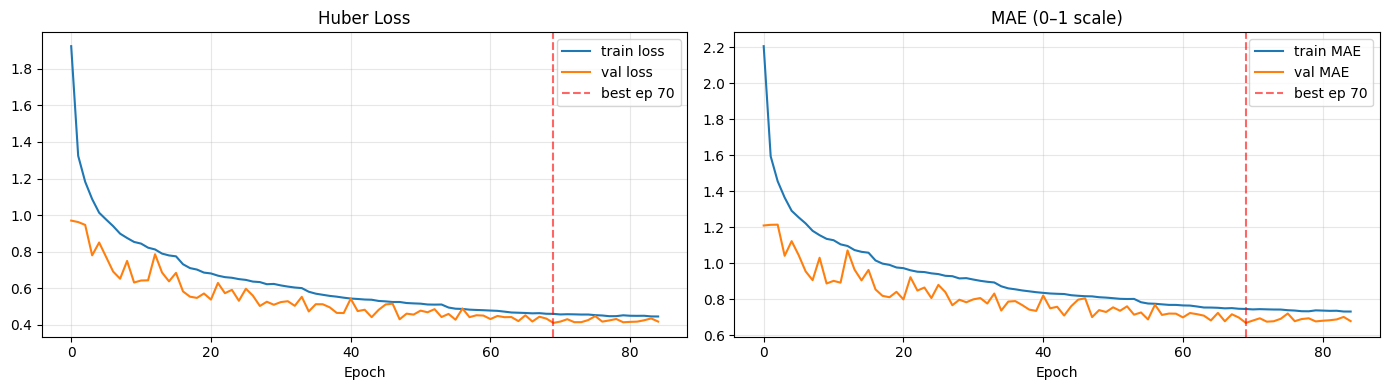

  Saved: /kaggle/working/training_curves.png

[STEP 5] Evaluating on test set...
563/563 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step

  SunNET 2D CNN — TEST SET RESULTS
  MAE   : 1.2792
  RMSE  : 1.6787
  R²    : 0.9413
  nRMSE : 6.45%
────────────────────────────────────────────────
  nRMSE guide:  <10% excellent  |  10-20% good
                20-30% acceptable  |  >30% poor


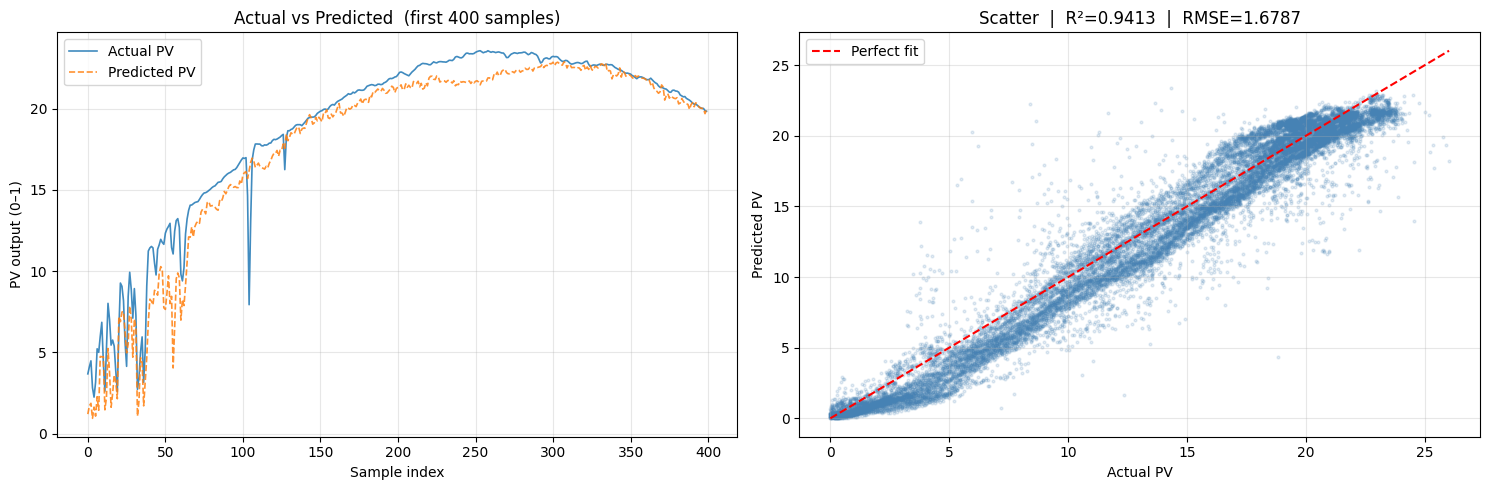

  Saved: /kaggle/working/pred_vs_actual.png


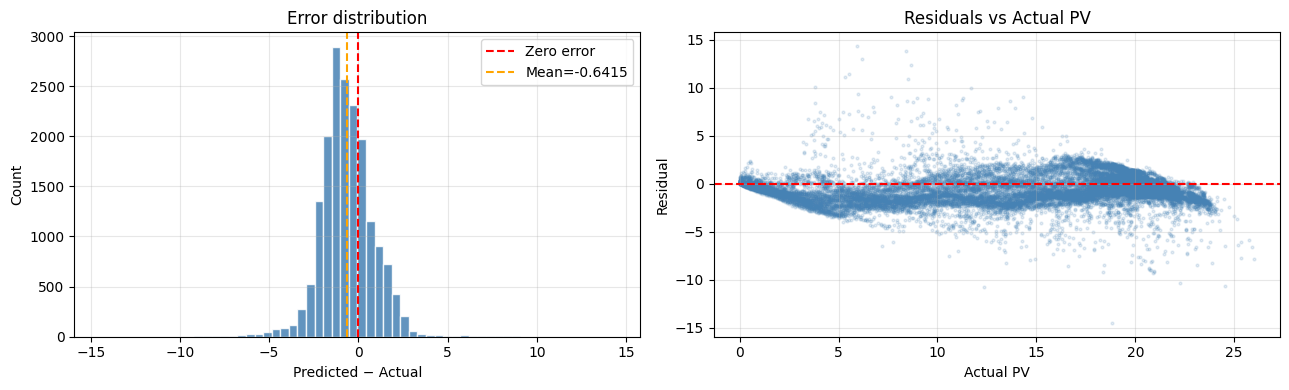

  Saved: /kaggle/working/error_dist.png


In [11]:
# ============================================================
#  SunNET 2D CNN — Complete Pipeline (error-free)
#  Data   : SKIPPD 2019, saved as .npy in processed_data
#  Input  : (64, 64, 3)  uint8 sky images
#  Labels : float32 PV already in [0, 1]
#  GPU    : Kaggle P100
# ============================================================

import numpy as np
import os
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, backend as K
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# ── reproducibility ──────────────────────────────────────────
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

# ── mixed precision ───────────────────────────────────────────
tf.keras.mixed_precision.set_global_policy("mixed_float16")
print(f"Compute dtype  : {tf.keras.mixed_precision.global_policy().compute_dtype}")
print(f"Variable dtype : {tf.keras.mixed_precision.global_policy().variable_dtype}")

# ── constants ─────────────────────────────────────────────────
IMG_H, IMG_W, IMG_C = 64, 64, 3
BATCH    = 32
L2_REG   = 1e-4
DROP     = 0.3
AUTOTUNE = tf.data.AUTOTUNE

# ============================================================
#  SECTION 1 — LOAD DATA
# ============================================================

DATA_DIR = '/kaggle/working/processed_data'

print("\n[STEP 1] Loading datasets...")
X_train = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
X_val   = np.load(os.path.join(DATA_DIR, 'X_val.npy'))
X_test  = np.load(os.path.join(DATA_DIR, 'X_test.npy'))
y_train = np.load(os.path.join(DATA_DIR, 'y_train.npy')).astype(np.float32)
y_val   = np.load(os.path.join(DATA_DIR, 'y_val.npy')).astype(np.float32)
y_test  = np.load(os.path.join(DATA_DIR, 'y_test.npy')).astype(np.float32)

print(f"  X_train : {X_train.shape}  dtype={X_train.dtype}")
print(f"  X_val   : {X_val.shape}    dtype={X_val.dtype}")
print(f"  X_test  : {X_test.shape}   dtype={X_test.dtype}")
print(f"  y range : [{y_train.min():.4f}, {y_train.max():.4f}]  (already 0-1, no scaling needed)")

# ============================================================
#  SECTION 2 — tf.data PIPELINE
# ============================================================

print("\n[STEP 2] Building tf.data pipelines...")

def preprocess(x, y):
    x = tf.cast(x, tf.float32) / 255.0
    return x, y

def augment(x, y):
    x = tf.cast(x, tf.float32) / 255.0
    x = tf.image.random_flip_left_right(x)
    x = tf.image.random_flip_up_down(x)
    x = tf.image.random_brightness(x, max_delta=0.04)
    x = tf.image.random_contrast(x, lower=0.95, upper=1.05)
    x = tf.clip_by_value(x, 0.0, 1.0)
    return x, y

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=5000, seed=SEED)
    .map(augment,    num_parallel_calls=AUTOTUNE)
    .batch(BATCH,    drop_remainder=True)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH,    drop_remainder=False)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH,    drop_remainder=False)
    .prefetch(AUTOTUNE)
)

for xb, yb in train_ds.take(1):
    print(f"  Train batch  X:{xb.shape} {xb.dtype}   y:{yb.shape} {yb.dtype}")

# ============================================================
#  SECTION 3 — BUILDING BLOCKS
#  KEY FIX: spatial_attention uses Lambda layers instead of
#  raw tf.reduce_mean / tf.reduce_max on KerasTensors
# ============================================================

def conv_bn_relu(x, filters, kernel=3, name=""):
    x = layers.Conv2D(
        filters, kernel_size=kernel, padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(L2_REG),
        name=f"{name}_conv"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn")(x)
    x = layers.Activation("relu", name=f"{name}_relu")(x)
    return x


def res_block(x, filters, name="res"):
    shortcut = x

    x = conv_bn_relu(x, filters, kernel=3, name=f"{name}_a")
    x = layers.Conv2D(
        filters, kernel_size=3, padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(L2_REG),
        name=f"{name}_b_conv"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_b_bn")(x)

    # 1x1 projection if channel dims differ
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, kernel_size=1, padding="same",
            use_bias=False, name=f"{name}_proj"
        )(shortcut)
        shortcut = layers.BatchNormalization(name=f"{name}_proj_bn")(shortcut)

    x = layers.Add(name=f"{name}_add")([x, shortcut])
    x = layers.Activation("relu", name=f"{name}_out")(x)
    return x


def channel_attention(x, ratio=8, name="ca"):
    """
    Squeeze-and-Excitation.
    GlobalAvgPool and GlobalMaxPool are Keras layers — no issue.
    """
    C   = x.shape[-1]
    gap = layers.GlobalAveragePooling2D(name=f"{name}_gap")(x)
    gmp = layers.GlobalMaxPooling2D(name=f"{name}_gmp")(x)

    def excite(v, suffix):
        v = layers.Dense(
            C // ratio, activation="relu",
            kernel_regularizer=regularizers.l2(L2_REG),
            name=f"{name}_fc1_{suffix}"
        )(v)
        return layers.Dense(C, name=f"{name}_fc2_{suffix}")(v)

    att = layers.Add(name=f"{name}_sum")([excite(gap, "gap"), excite(gmp, "gmp")])
    att = layers.Activation("sigmoid", name=f"{name}_sig")(att)
    att = layers.Reshape((1, 1, C), name=f"{name}_rs")(att)
    return layers.Multiply(name=f"{name}_out")([x, att])


def spatial_attention(x, name="sa"):
    """
    CBAM spatial attention.
    FIX: tf.reduce_mean / tf.reduce_max wrapped in Lambda layers
    so they work correctly inside Keras Functional API.
    """
    # Lambda wraps the raw tf ops — this is the correct pattern
    avg_f = layers.Lambda(
        lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
        name=f"{name}_avg"
    )(x)
    max_f = layers.Lambda(
        lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
        name=f"{name}_max"
    )(x)

    cat = layers.Concatenate(axis=-1, name=f"{name}_cat")([avg_f, max_f])
    att = layers.Conv2D(
        1, kernel_size=7, padding="same",
        use_bias=False, name=f"{name}_conv"
    )(cat)
    att = layers.Activation("sigmoid", name=f"{name}_sig")(att)
    return layers.Multiply(name=f"{name}_out")([x, att])


# ============================================================
#  SECTION 4 — SunNET 2D CNN
#
#  (64,64,3)
#    Block1 ResConv(32)  + MaxPool + SpatialDropout → 32×32×32
#    Block2 ResConv(64)  + MaxPool + SpatialDropout → 16×16×64
#    Block3 ResConv(128) + MaxPool + SpatialDropout →  8×8×128
#    Block4 ResConv(256) + MaxPool                  →  4×4×256
#    Channel Attention (SE)
#    Spatial Attention (CBAM) ← fixed
#    GAP + GMP concat → 512-d
#    Dense(256,BN,Drop) → Dense(128,BN,Drop) → Dense(64,Drop) → Dense(1)
# ============================================================

def build_sunnet(input_shape=(IMG_H, IMG_W, IMG_C)):

    inp = layers.Input(shape=input_shape, name="image_input")

    # Block 1: 64→32
    x = res_block(inp, 32,  name="b1")
    x = layers.MaxPooling2D(2, name="pool1")(x)
    x = layers.SpatialDropout2D(0.10, name="sdrop1")(x)

    # Block 2: 32→16
    x = res_block(x,   64,  name="b2")
    x = layers.MaxPooling2D(2, name="pool2")(x)
    x = layers.SpatialDropout2D(0.10, name="sdrop2")(x)

    # Block 3: 16→8
    x = res_block(x,   128, name="b3")
    x = layers.MaxPooling2D(2, name="pool3")(x)
    x = layers.SpatialDropout2D(0.15, name="sdrop3")(x)

    # Block 4: 8→4
    x = res_block(x,   256, name="b4")
    x = layers.MaxPooling2D(2, name="pool4")(x)

    # Dual attention
    x = channel_attention(x, ratio=8, name="ca")
    x = spatial_attention(x,          name="sa")

    # GAP + GMP → concat 512-d
    gap = layers.GlobalAveragePooling2D(name="gap")(x)
    gmp = layers.GlobalMaxPooling2D(name="gmp")(x)
    x   = layers.Concatenate(name="pool_concat")([gap, gmp])

    # Regression head
    x = layers.Dense(
        256, activation="relu",
        kernel_regularizer=regularizers.l2(L2_REG),
        name="dense1"
    )(x)
    x = layers.BatchNormalization(name="head_bn1")(x)
    x = layers.Dropout(DROP, name="drop1")(x)

    x = layers.Dense(
        128, activation="relu",
        kernel_regularizer=regularizers.l2(L2_REG),
        name="dense2"
    )(x)
    x = layers.BatchNormalization(name="head_bn2")(x)
    x = layers.Dropout(DROP * 0.6, name="drop2")(x)

    x = layers.Dense(
        64, activation="relu",
        kernel_regularizer=regularizers.l2(L2_REG),
        name="dense3"
    )(x)
    x = layers.Dropout(0.1, name="drop3")(x)

    # Output — force float32 even under mixed precision
    out = layers.Dense(
        1, activation="linear",
        dtype="float32",
        name="pv_output"
    )(x)

    return models.Model(inputs=inp, outputs=out, name="SunNET_2DCNN")


# ============================================================
#  SECTION 5 — BUILD & COMPILE
# ============================================================

print("\n[STEP 3] Building SunNET...")
model = build_sunnet()
model.summary(line_length=80)
print(f"\n  Total parameters : {model.count_params():,}")

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=3e-4,
        clipnorm=1.0
    ),
    loss=tf.keras.losses.Huber(delta=1.0),
    metrics=["mae"]
)

# ============================================================
#  SECTION 6 — CALLBACKS
# ============================================================

CKPT = '/kaggle/working/sunnet_best.keras'

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        CKPT,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=6,
        min_lr=1e-7,
        verbose=1
    ),
]

# ============================================================
#  SECTION 7 — TRAIN
# ============================================================

print("\n[STEP 4] Training...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=callbacks,
    verbose=1
)

best_ep = int(np.argmin(history.history['val_loss'])) + 1
print(f"\n  Best epoch    : {best_ep}")
print(f"  Best val_loss : {min(history.history['val_loss']):.6f}")
print(f"  Best val_mae  : {min(history.history['val_mae']):.6f}")

# ============================================================
#  SECTION 8 — TRAINING CURVES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(history.history['loss'],     label='train loss', lw=1.5)
axes[0].plot(history.history['val_loss'], label='val loss',   lw=1.5)
axes[0].axvline(best_ep-1, color='red', ls='--', alpha=0.6,
                label=f'best ep {best_ep}')
axes[0].set_title('Huber Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['mae'],     label='train MAE', lw=1.5)
axes[1].plot(history.history['val_mae'], label='val MAE',   lw=1.5)
axes[1].axvline(best_ep-1, color='red', ls='--', alpha=0.6,
                label=f'best ep {best_ep}')
axes[1].set_title('MAE (0–1 scale)')
axes[1].set_xlabel('Epoch')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print("  Saved: /kaggle/working/training_curves.png")

# ============================================================
#  SECTION 9 — EVALUATE ON TEST SET
# ============================================================

print("\n[STEP 5] Evaluating on test set...")
preds  = model.predict(test_ds, verbose=1).flatten()
n      = min(len(preds), len(y_test))
preds  = preds[:n]
y_true = y_test[:n]

mae   = mean_absolute_error(y_true, preds)
mse   = mean_squared_error(y_true, preds)
rmse  = np.sqrt(mse)
ss_res = np.sum((y_true - preds) ** 2)
ss_tot = np.sum((y_true - y_true.mean()) ** 2)
r2    = 1.0 - ss_res / (ss_tot + 1e-8)
nrmse = (rmse / (y_true.max() - y_true.min())) * 100.0

print("\n" + "=" * 48)
print("  SunNET 2D CNN — TEST SET RESULTS")
print("=" * 48)
print(f"  MAE   : {mae:.4f}")
print(f"  RMSE  : {rmse:.4f}")
print(f"  R²    : {r2:.4f}")
print(f"  nRMSE : {nrmse:.2f}%")
print("─" * 48)
print(f"  nRMSE guide:  <10% excellent  |  10-20% good")
print(f"                20-30% acceptable  |  >30% poor")
print("=" * 48)

# ============================================================
#  SECTION 10 — PREDICTION vs ACTUAL PLOTS
# ============================================================

n_plot = min(400, n)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(y_true[:n_plot], label='Actual PV',    lw=1.2, alpha=0.85)
axes[0].plot(preds[:n_plot],  label='Predicted PV', lw=1.2, alpha=0.85, ls='--')
axes[0].set_title(f'Actual vs Predicted  (first {n_plot} samples)')
axes[0].set_xlabel('Sample index')
axes[0].set_ylabel('PV output (0–1)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

mn = min(y_true.min(), preds.min())
mx = max(y_true.max(), preds.max())
axes[1].scatter(y_true, preds, alpha=0.15, s=4,
                color='steelblue', rasterized=True)
axes[1].plot([mn, mx], [mn, mx], 'r--', lw=1.5, label='Perfect fit')
axes[1].set_title(f'Scatter  |  R²={r2:.4f}  |  RMSE={rmse:.4f}')
axes[1].set_xlabel('Actual PV')
axes[1].set_ylabel('Predicted PV')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/pred_vs_actual.png', dpi=120, bbox_inches='tight')
plt.show()
print("  Saved: /kaggle/working/pred_vs_actual.png")

# ── error distribution ────────────────────────────────────────
errors = preds - y_true
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(errors, bins=60, color='steelblue',
             edgecolor='white', alpha=0.85)
axes[0].axvline(0,             color='red',    ls='--', label='Zero error')
axes[0].axvline(errors.mean(), color='orange', ls='--',
                label=f'Mean={errors.mean():.4f}')
axes[0].set_title('Error distribution')
axes[0].set_xlabel('Predicted − Actual')
axes[0].set_ylabel('Count')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].scatter(y_true, errors, alpha=0.15, s=4,
                color='steelblue', rasterized=True)
axes[1].axhline(0, color='red', ls='--')
axes[1].set_title('Residuals vs Actual PV')
axes[1].set_xlabel('Actual PV')
axes[1].set_ylabel('Residual')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/error_dist.png', dpi=120, bbox_inches='tight')
plt.show()
print("  Saved: /kaggle/working/error_dist.png")